# Assignment 2: Diabetes Classification

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('diabetes_binary_classification_data.csv')

# All values are whole numbers stored as floats, so we store them as integers
df = df.astype(int)

print(df.shape)
df.head()

(253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,...,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,...,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,...,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,...,1,0,2,3,0,0,0,11,5,4


# Step 1 - Understand the data

## Features and target

- **Target (y):** `Diabetes_binary`
- **Input features (X):** the other 21 columns

In [2]:
X = df.drop(columns=['Diabetes_binary'])
y = df['Diabetes_binary']

print('X:', X.shape)
print('y:', y.shape)
print('Missing values:', df.isna().sum().sum())

X: (253680, 21)
y: (253680,)
Missing values: 0


## What do class 0 and class 1 mean?

- **0** = no diabetes
- **1** = prediabetes or diabetes

Class 1 combines prediabetes and diabetes, so the model cannot tell them apart.

## How many observations are in each class?

In [3]:
class_counts = pd.DataFrame({
    'Count': y.value_counts(),
    'Proportion': y.value_counts(normalize=True).round(3),
})
class_counts

,Count,Proportion
Diabetes_binary,,
0,218334,0.861
1,35346,0.139


The target is **imbalanced**: only about 14% are class 1. A model that always predicts "no diabetes" would already be about 86% accurate, so accuracy alone is not enough to judge the model. We also need precision and recall.

## Three features of different types

All columns are stored as numbers, but the numbers mean different things. We use the *Understanding the Dataset* guide to read them:

| Feature | Type | What the values mean |
|---|---|---|
| `BMI` | Numerical | Body Mass Index, a real measurement (12-98) |
| `HighBP` | Binary | 0 = no high blood pressure, 1 = high blood pressure |
| `GenHlth` | Ordered | Self-rated health: 1 = excellent, 2 = very good, 3 = good, 4 = fair, 5 = poor |

In [4]:
print(df['BMI'].describe().round(1), '\n')
print(df['HighBP'].value_counts().sort_index(), '\n')
print(df['GenHlth'].value_counts().sort_index())

count    253680.0
mean         28.4
std           6.6
min          12.0
25%          24.0
50%          27.0
75%          31.0
max          98.0
Name: BMI, dtype: float64 

HighBP
0    144851
1    108829
Name: count, dtype: int64 

GenHlth
1    45299
2    89084
3    75646
4    31570
5    12081
Name: count, dtype: int64


- `BMI` is a real amount, so a higher number means a higher BMI.
- `HighBP` is a yes/no answer, so 0 and 1 are two categories, not amounts.
- `GenHlth` has an order (higher = worse health), but the steps between codes are not measured distances. A 4 is not "twice as bad" as a 2.

So looking only at the numbers in the CSV is not enough. The same kind of number can be a measurement, a category or an ordered group.

# Step 2 - Explore the data

We explore every feature against `Diabetes_binary`, using a method that fits each feature type:

- **Numerical:** compare the distributions for class 0 and class 1.
- **Binary:** compare the share with diabetes when the feature is 0 vs 1.
- **Ordered:** see how the share with diabetes changes across the categories.

EDA shows associations in this data. It does not show that a feature causes diabetes.

In [5]:
numerical = ['BMI', 'MentHlth', 'PhysHlth']
binary = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack',
          'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare',
          'NoDocbcCost', 'DiffWalk', 'Sex']
ordered = ['GenHlth', 'Age', 'Education', 'Income']

# Colors: blue for class 0 / "no", orange for class 1 / "yes"
BLUE, ORANGE, GRID = '#2a78d6', '#e0742b', '#e5e5e3'
overall_rate = y.mean()
print(f'Share with diabetes overall: {overall_rate:.1%}')

Share with diabetes overall: 13.9%


## Numerical features

In [6]:
df.groupby('Diabetes_binary')[numerical].describe().T.round(1)

Diabetes_binary         0        1
BMI      count   218334.0  35346.0
         mean        27.8     31.9
         std          6.3      7.4
         min         12.0     13.0
         25%         24.0     27.0
         50%         27.0     31.0
         75%         31.0     35.0
         max         98.0     98.0
MentHlth count   218334.0  35346.0
         mean         3.0      4.5
         std          7.1      8.9
         min          0.0      0.0
         25%          0.0      0.0
         50%          0.0      0.0
         75%          2.0      3.0
         max         30.0     30.0
PhysHlth count   218334.0  35346.0
         mean         3.6      8.0
         std          8.1     11.3
         min          0.0      0.0
         25%          0.0      0.0
         50%          0.0      1.0
         75%          2.0     15.0
         max         30.0     30.0

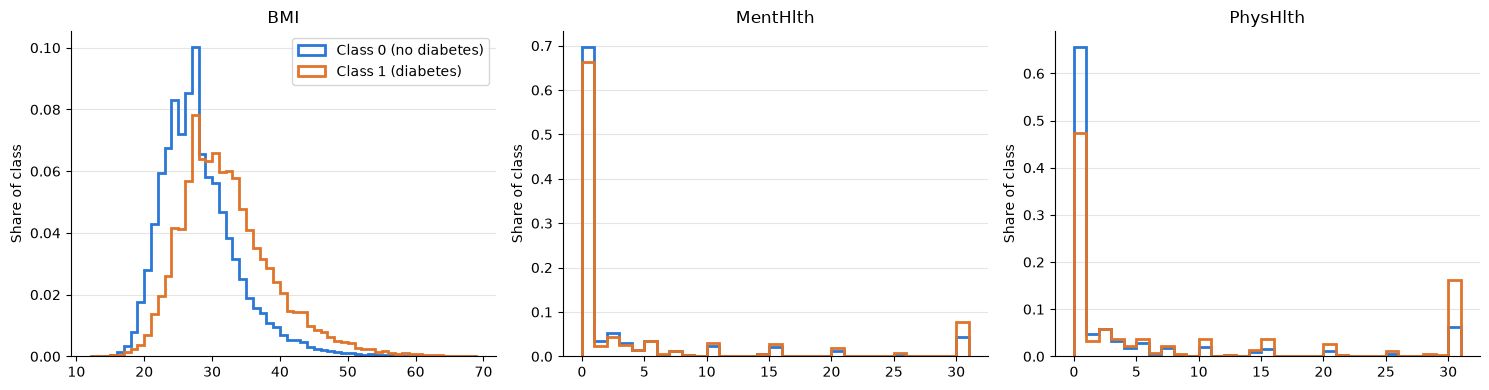

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bins = {'BMI': range(12, 70), 'MentHlth': range(0, 32), 'PhysHlth': range(0, 32)}

for ax, col in zip(axes, numerical):
    for cls, color, label in [(0, BLUE, 'Class 0 (no diabetes)'), (1, ORANGE, 'Class 1 (diabetes)')]:
        ax.hist(df.loc[y == cls, col], bins=bins[col], density=True,
                histtype='step', linewidth=2, color=color, label=label)
    ax.set_title(col)
    ax.set_ylabel('Share of class')
    ax.set_axisbelow(True)
    ax.grid(axis='y', color=GRID)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].legend()
plt.tight_layout()
plt.show()

- `BMI` is shifted to the right for class 1 (median 31 vs 27).
- `MentHlth` and `PhysHlth` are mostly 0, with a spike at 30 (people who answered "every day"). `PhysHlth` differs more between the classes than `MentHlth`.
- BMI goes up to 98, but values above about 60 are rare (805 people), so we keep them.

The histograms show each class as a share of its own class, because class 1 is much smaller.

## Binary features

In [8]:
binary_table = pd.DataFrame({
    'Share with feature = 1': df[binary].mean(),
    'Diabetes share when 0': [y[df[col] == 0].mean() for col in binary],
    'Diabetes share when 1': [y[df[col] == 1].mean() for col in binary],
})
binary_table['Difference'] = binary_table['Diabetes share when 1'] - binary_table['Diabetes share when 0']
binary_table = binary_table.sort_values('Difference')
binary_table.round(3)

,Share with feature = 1,Diabetes share when 0,Diabetes share when 1,Difference
PhysActivity,0.757,0.211,0.116,-0.095
HvyAlcoholConsump,0.056,0.144,0.058,-0.086
Veggies,0.811,0.180,0.130,-0.050
Fruits,0.634,0.158,0.129,-0.029
Sex,0.440,0.130,0.152,0.022
AnyHealthcare,0.951,0.115,0.141,0.026
NoDocbcCost,0.084,0.136,0.175,0.039
Smoker,0.443,0.121,0.163,0.042
CholCheck,0.963,0.025,0.144,0.118
HighChol,0.424,0.080,0.220,0.140


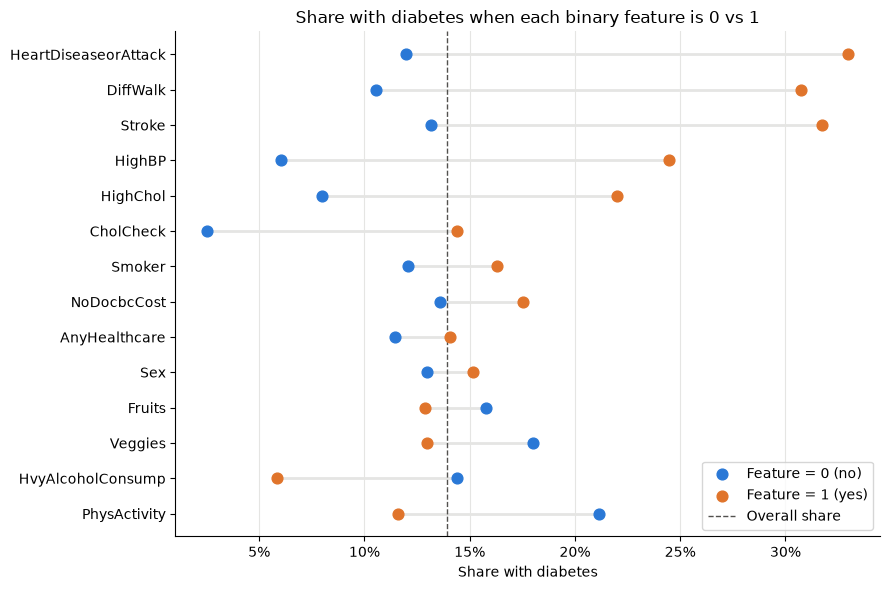

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
rows = range(len(binary_table))

ax.hlines(rows, binary_table['Diabetes share when 0'], binary_table['Diabetes share when 1'],
          color=GRID, linewidth=2)
ax.scatter(binary_table['Diabetes share when 0'], rows, s=60, color=BLUE, label='Feature = 0 (no)', zorder=3)
ax.scatter(binary_table['Diabetes share when 1'], rows, s=60, color=ORANGE, label='Feature = 1 (yes)', zorder=3)
ax.axvline(overall_rate, color='#52514e', linestyle='--', linewidth=1, label='Overall share')

ax.set_yticks(list(rows))
ax.set_yticklabels(binary_table.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xlabel('Share with diabetes')
ax.set_title('Share with diabetes when each binary feature is 0 vs 1')
ax.set_axisbelow(True)
ax.grid(axis='x', color=GRID)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

- Health conditions show the biggest differences: people with heart disease, walking difficulty, a stroke, high blood pressure or high cholesterol have a much higher diabetes share.
- `CholCheck`: only 2.5% of people without a cholesterol check in the last 5 years have diabetes. This is probably because people with diabetes see a doctor more often, not because the check protects them.
- `PhysActivity`, `Veggies`, `Fruits` and `HvyAlcoholConsump` go the other way: the diabetes share is lower when the answer is "yes".
- `Sex`, `AnyHealthcare`, `NoDocbcCost` and `Smoker` show only small differences.
- Some features are very unbalanced. For example, 96% have had a cholesterol check and only 6% are heavy drinkers.

## Ordered features

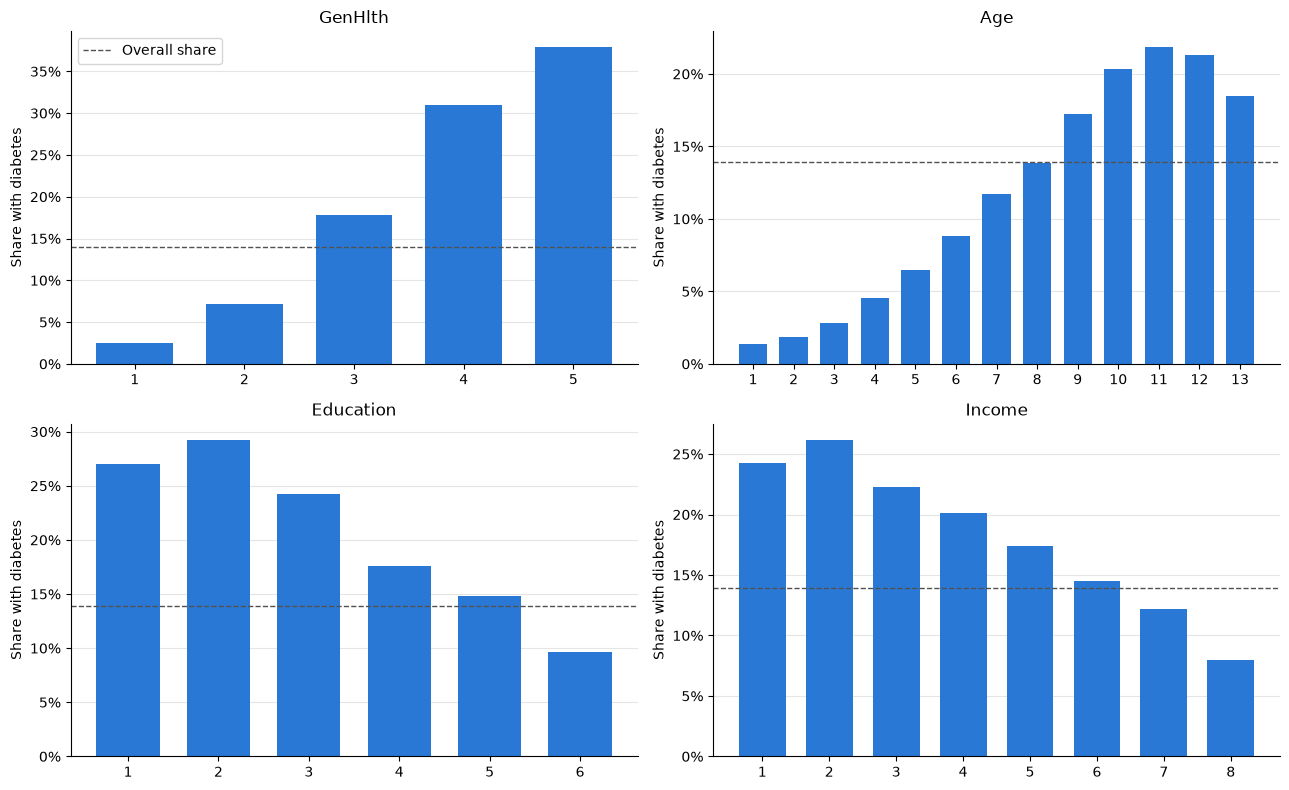

GenHlth {1: 45299, 2: 89084, 3: 75646, 4: 31570, 5: 12081}
Age {1: 5700, 2: 7598, 3: 11123, 4: 13823, 5: 16157, 6: 19819, 7: 26314, 8: 30832, 9: 33244, 10: 32194, 11: 23533, 12: 15980, 13: 17363}
Education {1: 174, 2: 4043, 3: 9478, 4: 62750, 5: 69910, 6: 107325}
Income {1: 9811, 2: 11783, 3: 15994, 4: 20135, 5: 25883, 6: 36470, 7: 43219, 8: 90385}


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, col in zip(axes.flat, ordered):
    rate = df.groupby(col)['Diabetes_binary'].mean()
    ax.bar(rate.index, rate.values, color=BLUE, width=0.7)
    ax.axhline(overall_rate, color='#52514e', linestyle='--', linewidth=1, label='Overall share')
    ax.set_title(col)
    ax.set_xticks(rate.index)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.set_ylabel('Share with diabetes')
    ax.set_axisbelow(True)
    ax.grid(axis='y', color=GRID)
    ax.spines[['top', 'right']].set_visible(False)

axes[0, 0].legend()
plt.tight_layout()
plt.show()

for col in ordered:
    print(col, df[col].value_counts().sort_index().to_dict())

Codes are explained in the guide. For example, `GenHlth` 1 = excellent and 5 = poor; `Age` 1 = 18-24 and 13 = 80+.

- `GenHlth`: the diabetes share rises steadily from excellent to poor health.
- `Age`: the share rises with age up to about 70-74, then flattens.
- `Education` and `Income`: the share falls as education and income go up.
- Some categories are small, for example only 174 people have `Education` = 1.

## Main findings

**1. Is self-rated health related to diabetes?**
- *Evidence:* the `GenHlth` plot. The diabetes share goes from 2.5% (excellent) to 38% (poor).
- *Conclusion:* `GenHlth` has the clearest relationship with the target and looks useful for prediction.
- *We cannot conclude* that poor health causes diabetes. Having diabetes could also make people rate their health as worse.

**2. Are other health conditions related to diabetes?**
- *Evidence:* the binary plot. With high blood pressure the share is 24%, vs 6% without. Heart disease, stroke and walking difficulty show similar gaps.
- *Conclusion:* these conditions often appear together with diabetes in this data.
- *We cannot conclude* which one comes first, or that one causes another.

**3. Does BMI differ between the classes?**
- *Evidence:* the BMI histogram and the table below. The share with diabetes rises from about 6% for BMI under 25 to 34% for BMI over 40.
- *Conclusion:* higher BMI is associated with diabetes.

**4. Does the diabetes share change with age?**
- *Evidence:* the `Age` plot. It rises from about 1% in the youngest group to about 22% at ages 70-74.
- *Conclusion:* age is strongly associated with diabetes.

**5. Which features show little relationship, or a surprising one?**
- *Evidence:* `Sex`, `AnyHealthcare`, `NoDocbcCost` and `Smoker` differ by only 2-4 percentage points. Heavy drinkers have a *lower* diabetes share (6% vs 14%).
- *Conclusion:* these features probably add less to the model.
- *We cannot conclude* that alcohol protects against diabetes. Other differences between the groups, such as age, could explain the pattern.

In [11]:
bmi_groups = pd.cut(df['BMI'], bins=[0, 18.5, 25, 30, 35, 40, 100],
                    labels=['<18.5', '18.5-25', '25-30', '30-35', '35-40', '40+'])
pd.DataFrame({
    'People': bmi_groups.value_counts().sort_index(),
    'Share with diabetes': df.groupby(bmi_groups, observed=True)['Diabetes_binary'].mean().round(3),
})

,People,Share with diabetes
BMI,,
<18.5,3127,0.054
18.5-25,86099,0.062
25-30,91176,0.127
30-35,44453,0.212
35-40,17346,0.285
40+,11479,0.338
